In [82]:
# Loading Dependencies
import numpy as np
import pandas as pd

In [83]:
# Data Loading and Categorising features
data=pd.read_csv(r'C:\Users\victory\Desktop\MACHINE LEARNING PROJECTS\Neural_network_from_scratch\data\mnist_test.csv', encoding='latin-1')
data=np.array(data)
label=data[:,0]
X_value=data[:,1:785]

In [84]:
# Data Splitting
X_test=X_value[0:2000]
Y_test=label[0:2000]
X_train=X_value[2000:]
Y_train=label[2000:]
X_train = X_train.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
one_hot_label=np.eye(10)[Y_train].T

In [85]:
# Forward Propagation
def params():
    w1 = np.random.randn(10,784) * np.sqrt(2/784)
    b1 = np.zeros((10,1))

    w2 = np.random.randn(10,10) * np.sqrt(2/10)
    b2 = np.zeros((10,1))

    m,n = X_train.shape
    return w1,b1,w2,b2,m,n

def relu(z):
    g=np.maximum(0,z)
    return g

def softmax(x):
    x = x - np.max(x, axis=0, keepdims=True)
    exp_values=np.exp(x)
    sm= exp_values/ np.sum(exp_values, axis=0, keepdims=True)
    return sm

def layers(w1,b1,w2,b2,X):
    z1=w1.dot(X.T)+b1
    y1=relu(z1)
    z2=np.dot(w2,y1)+b2
    y2=softmax(z2)
    return y2,y1,z2,z1


# Back propagation
def loss_function(y, A):
    m = y.shape[1]
    n_classes = y.shape[0]

    total_loss = 0
    log_A = np.log(np.clip(A, 1e-12, 1.0))

    for i in range(m):
        image_loss = 0
        for j in range(n_classes):
            image_loss += y[j, i] * log_A[j, i]

        total_loss += image_loss

    return -total_loss / m

def deriv_relu(z):
   return z>0
  
def gradient_updates(A2,A1,z1,y,w2,X_train):
   dz=A2-y
   dw2=(1/m)*np.dot(dz,A1.T)
   db2=(1/m)*np.sum(dz,axis=1,keepdims=True)
   dz1=np.dot(w2.T,dz)*deriv_relu(z1)
   dw1=(1/m)*np.dot(dz1,X_train)
   db1=(1/m)*np.sum(dz1,axis=1,keepdims=True)
   return dw2,db2,dw1,db1

def gradient_descent(lr,w1,b1,w2,b2,dw1,db1,dw2,db2):
   w1=w1-lr*dw1
   b1=b1-lr*db1
   w2=w2-lr*dw2
   b2=b2-lr*db2
   return w1,b1,w2,b2



In [86]:
def accuracy(A2, Y):
    predictions = np.argmax(A2, axis=0)
    actual = np.argmax(Y, axis=0)

    return np.mean(predictions == actual)

w1, b1, w2, b2 ,m ,n=params()

# Training and accuracy 
for i in range(500):
    A2, A1, Z1, Z2= layers(w1, b1, w2, b2, X_train)

    loss = loss_function(one_hot_label, A2)

    dw2, db2, dw1, db1 = gradient_updates(
        A2, A1, Z1, one_hot_label, w2, X_train
    )

    w1,b1, w2, b2 = gradient_descent(
        0.1,w1,b1,w2,b2,dw1, db1, dw2, db2
    )

    print(f"Iteration {i+1}, Loss: {loss:.4f}")
    print("Accuracy:", accuracy(A2, one_hot_label))
    

Iteration 1, Loss: 2.3696
Accuracy: 0.10475
Iteration 2, Loss: 2.2964
Accuracy: 0.1315
Iteration 3, Loss: 2.2485
Accuracy: 0.14425
Iteration 4, Loss: 2.2025
Accuracy: 0.164125
Iteration 5, Loss: 2.1586
Accuracy: 0.189375
Iteration 6, Loss: 2.1176
Accuracy: 0.211875
Iteration 7, Loss: 2.0806
Accuracy: 0.234125
Iteration 8, Loss: 2.0460
Accuracy: 0.256125
Iteration 9, Loss: 2.0139
Accuracy: 0.27675
Iteration 10, Loss: 1.9849
Accuracy: 0.29575
Iteration 11, Loss: 1.9591
Accuracy: 0.313
Iteration 12, Loss: 1.9359
Accuracy: 0.328125
Iteration 13, Loss: 1.9150
Accuracy: 0.3405
Iteration 14, Loss: 1.8972
Accuracy: 0.352
Iteration 15, Loss: 1.8818
Accuracy: 0.361625
Iteration 16, Loss: 1.8679
Accuracy: 0.3715
Iteration 17, Loss: 1.8555
Accuracy: 0.38
Iteration 18, Loss: 1.8445
Accuracy: 0.383375
Iteration 19, Loss: 1.8346
Accuracy: 0.389625
Iteration 20, Loss: 1.8251
Accuracy: 0.396
Iteration 21, Loss: 1.8159
Accuracy: 0.401125
Iteration 22, Loss: 1.8072
Accuracy: 0.4065
Iteration 23, Loss: 1.

In [87]:
one_hot_test = np.eye(10)[Y_test].T

A2_test, A1_test, Z1_test ,Z2_test= layers(
    w1, b1, w2, b2, X_test
)

print("Training accuracy:", accuracy(A2, one_hot_label))
print("Test accuracy:", accuracy(A2_test, one_hot_test))

Training accuracy: 0.75
Test accuracy: 0.718


3


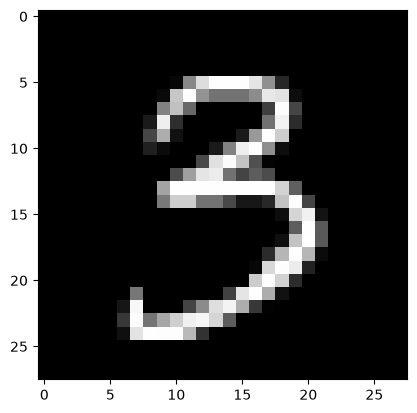

In [89]:
import matplotlib.pyplot as plt
X_train_=X_train[20].reshape(28,28)
plt.imshow(X_train_)
pred_val=np.argmax(A2, axis=0)
print(pred_val[20])